Sample mean = 5.760 min, Sample SD = 0.584
Degrees of freedom = 14
t statistic = 5.0395
t critical = ±2.1448
p-value = 0.000181

Decision: Reject H0 -> Average waiting time is significantly different from 5 minutes.


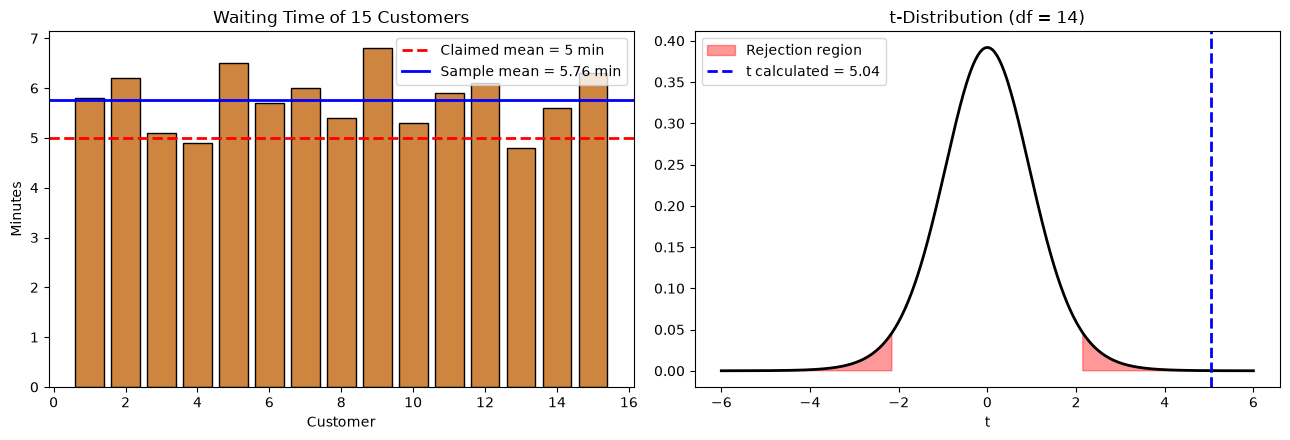

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Step 1: Data - waiting times (minutes) of 15 customers
wait = np.array([5.8, 6.2, 5.1, 4.9, 6.5, 5.7, 6.0, 5.4, 6.8, 5.3, 5.9, 6.1, 4.8, 5.6, 6.3])
mu0 = 5
alpha = 0.05
n = len(wait)
df = n - 1

# Step 2: t-test using scipy
t_stat, p_value = stats.ttest_1samp(wait, popmean=mu0)
t_critical = stats.t.ppf(1 - alpha/2, df)

print(f"Sample mean = {wait.mean():.3f} min, Sample SD = {wait.std(ddof=1):.3f}")
print(f"Degrees of freedom = {df}")
print(f"t statistic = {t_stat:.4f}")
print(f"t critical = ±{t_critical:.4f}")
print(f"p-value = {p_value:.6f}")

# Step 3: Decision
if p_value < alpha:
    print("\nDecision: Reject H0 -> Average waiting time is significantly different from 5 minutes.")
else:
    print("\nDecision: Fail to reject H0 -> No significant difference from 5 minutes.")

# Step 4: Graphs
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(range(1, n+1), wait, color='peru', edgecolor='black')
ax[0].axhline(mu0, color='red', linestyle='--', lw=2, label='Claimed mean = 5 min')
ax[0].axhline(wait.mean(), color='blue', linestyle='-', lw=2, label=f'Sample mean = {wait.mean():.2f} min')
ax[0].set_title('Waiting Time of 15 Customers')
ax[0].set_xlabel('Customer'); ax[0].set_ylabel('Minutes'); ax[0].legend()

x = np.linspace(-6, 6, 500)
y = stats.t.pdf(x, df)

ax[1].plot(x, y, 'k', lw=2)
ax[1].fill_between(x, y, where=(abs(x) >= t_critical), color='red', alpha=0.4, label='Rejection region')
ax[1].axvline(t_stat, color='blue', linestyle='--', lw=2, label=f't calculated = {t_stat:.2f}')
ax[1].set_title(f't-Distribution (df = {df})')
ax[1].set_xlabel('t'); ax[1].legend()

plt.tight_layout()
plt.show()

ONE-WAY ANOVA TABLE
Source                   SS     df         MS          F
Between groups        62.40      2      31.20     12.480
Within groups         30.00     12       2.50
Total                 92.40     14

F critical = 3.885, p-value = 0.001171
scipy f_oneway: F = 12.480, p = 0.001171
 Mean yield of Fertilizer A = 21.20
 Mean yield of Fertilizer B = 26.00
 Mean yield of Fertilizer C = 22.40

Decision: Reject H0 -> At least one fertilizer gives a significantly different mean yield.


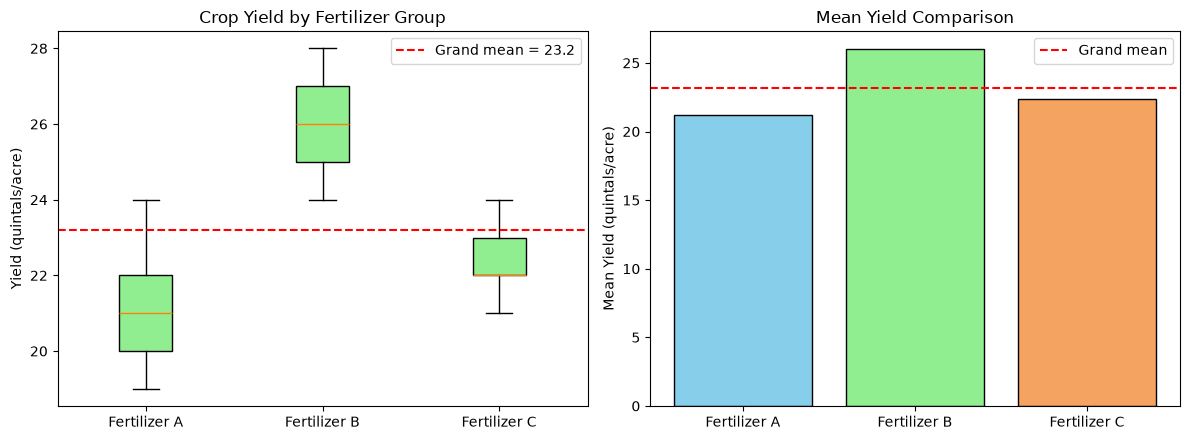

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Step 1: Data - yield (quintals/acre)
fert_A = np.array([20, 22, 19, 24, 21])
fert_B = np.array([25, 27, 24, 26, 28])
fert_C = np.array([22, 23, 21, 24, 22])
groups = [fert_A, fert_B, fert_C]
names = ['Fertilizer A', 'Fertilizer B', 'Fertilizer C']
alpha = 0.05

# Step 2: ANOVA calculations
all_data = np.concatenate(groups)
grand_mean = all_data.mean()
k, N = len(groups), len(all_data)

SSB = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups) # between
SSW = sum(((g - g.mean())**2).sum() for g in groups)          # within
SST = SSB + SSW

df_b, df_w = k - 1, N - k
MSB, MSW = SSB / df_b, SSW / df_w
F = MSB / MSW

p_value = 1 - stats.f.cdf(F, df_b, df_w)
F_critical = stats.f.ppf(1 - alpha, df_b, df_w)

print("ONE-WAY ANOVA TABLE")
print(f"{'Source':<16} {'SS':>10} {'df':>6} {'MS':>10} {'F':>10}")
print(f"{'Between groups':<16} {SSB:>10.2f} {df_b:>6} {MSB:>10.2f} {F:>10.3f}")
print(f"{'Within groups':<16} {SSW:>10.2f} {df_w:>6} {MSW:>10.2f}")
print(f"{'Total':<16} {SST:>10.2f} {N-1:>6}")

print(f"\nF critical = {F_critical:.3f}, p-value = {p_value:.6f}")

# Step 3: Check with scipy
F_scipy, p_scipy = stats.f_oneway(fert_A, fert_B, fert_C)
print(f"scipy f_oneway: F = {F_scipy:.3f}, p = {p_scipy:.6f}")

# Step 4: Decision
for name, g in zip(names, groups):
    print(f" Mean yield of {name} = {g.mean():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H0 -> At least one fertilizer gives a significantly different mean yield.")
else:
    print("\nDecision: Fail to reject H0 -> All fertilizers give the same mean yield.")

# Step 5: Graph
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].boxplot(groups, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
ax[0].set_xticks([1, 2, 3])
ax[0].set_xticklabels(names)
ax[0].axhline(grand_mean, color='red', linestyle='--', label=f'Grand mean = {grand_mean:.1f}')
ax[0].set_title('Crop Yield by Fertilizer Group')
ax[0].set_ylabel('Yield (quintals/acre)')
ax[0].legend()

means = [g.mean() for g in groups]
ax[1].bar(names, means, color=['skyblue', 'lightgreen', 'sandybrown'], edgecolor='black')
ax[1].axhline(grand_mean, color='red', linestyle='--', label='Grand mean')
ax[1].set_title('Mean Yield Comparison')
ax[1].set_ylabel('Mean Yield (quintals/acre)')
ax[1].legend()

plt.tight_layout()
plt.show()